# گام ۳: آمار توصیفی روی داده‌ی نمودارهای EDA
علی احمدی | بازی دوز

**وظیفه:** محاسبه میانگین، میانه، واریانس و انحراف معیار برای `nodes_minimax`، `nodes_alphabeta` و `moves`.

این نوت‌بوک همان آمار را برای هر نمودار از `eda.ipynb` که به این سه ستون مربوط است جداگانه حساب می‌کند:
**Q1** (گره‌ها)، **Q2** (خانه خالی و گره‌ها) و **Q5** (طول بازی). نمودارهای Q3، Q4 و Q6 دسته‌ای (categorical) هستند و میانگین و واریانس برایشان معنا ندارد.

واریانس و انحراف معیار با `pandas` به‌صورت **نمونه‌ای (n−1)** حساب شده‌اند.

## ۰. بارگذاری داده

In [1]:
import numpy as np
import pandas as pd

pd.set_option("display.float_format", "{:,.2f}".format)   # نمایش اعداد با جداکننده هزارگان

g = pd.read_csv("ttt_games.csv", dtype={"start_board": str})
print("شکل داده:", g.shape)
print("مقادیر گم‌شده:", int(g.isnull().sum().sum()))

شکل داده: (200, 10)
مقادیر گم‌شده: 0


## ۱. آمار کلی سه ستون

In [2]:
cols = ["nodes_minimax", "nodes_alphabeta", "moves"]
overall = g[cols].agg(["mean", "median", "var", "std", "min", "max"]).T
print(overall.to_string())

                      mean   median               var        std    min        max
nodes_minimax   120,069.26 6,812.00 46,819,846,902.58 216,378.94 113.00 549,946.00
nodes_alphabeta   4,382.18   427.00     49,979,724.68   7,069.63  30.00  18,297.00
moves                 4.56     4.50              2.69       1.64   1.00       9.00


## ۲. نمودار Q1-A: توزیع گره‌ها (جعبه‌ای، مقیاس لگاریتمی)
آماره‌های خود نمودار جعبه‌ای (Q1، میانه، Q3، کمینه، بیشینه) در کنار میانگین و واریانس:

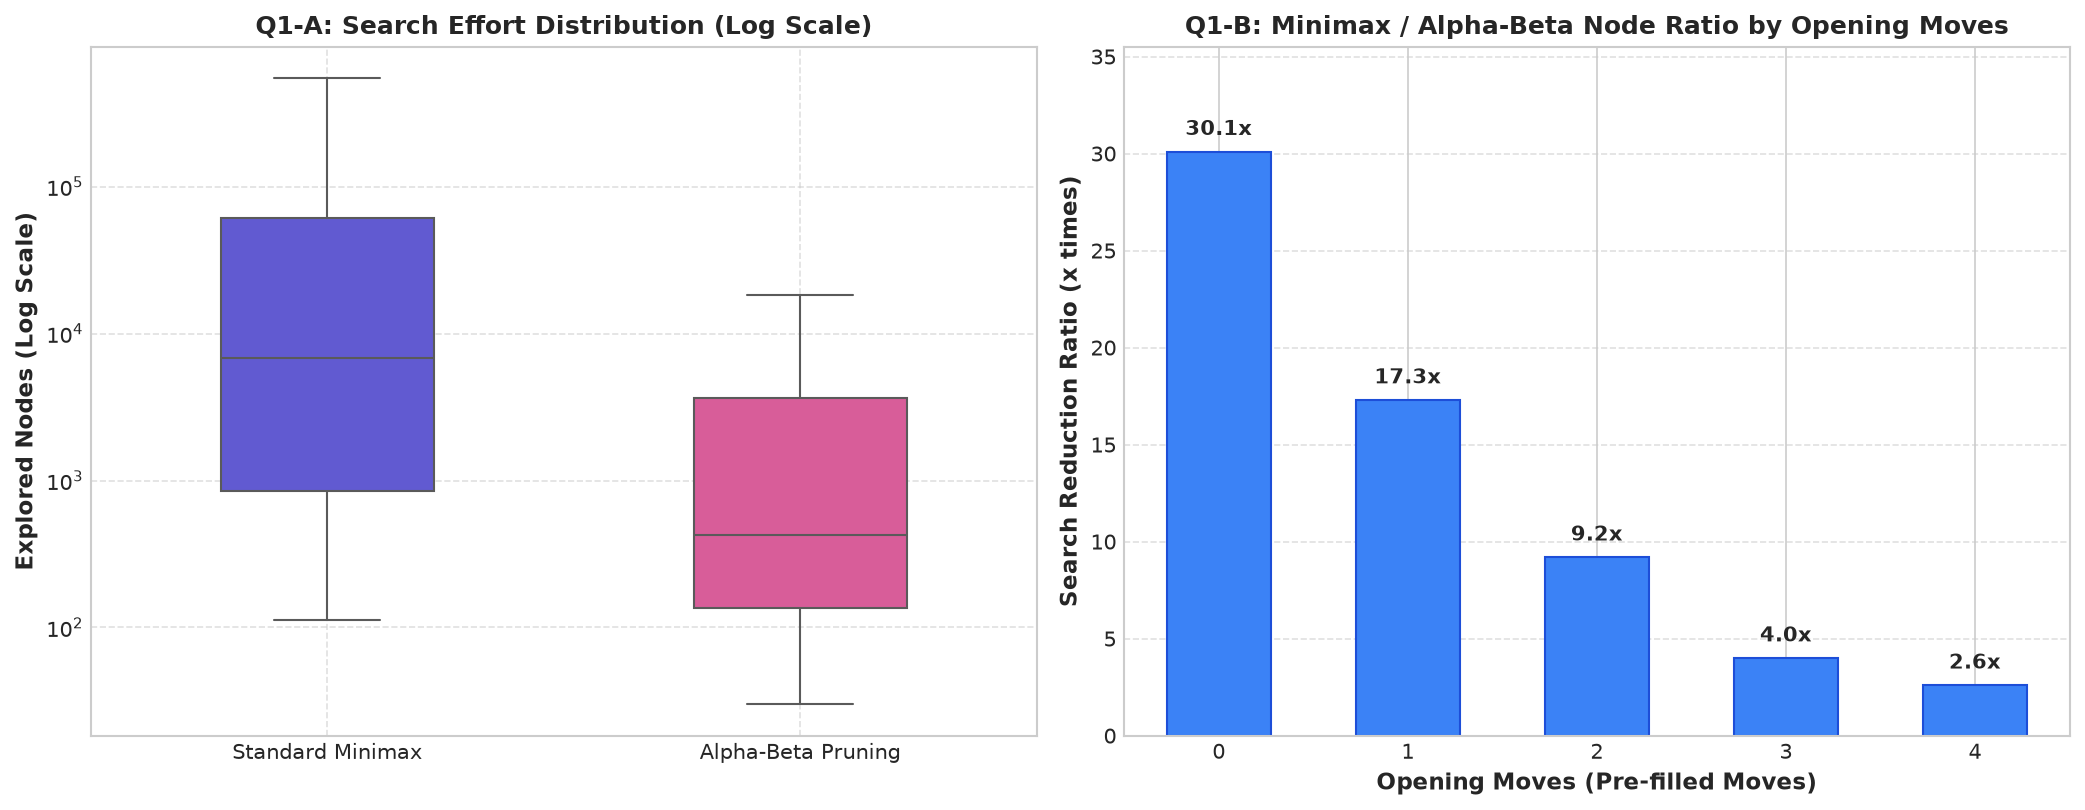

In [3]:
rows = {}
for c in ["nodes_minimax", "nodes_alphabeta"]:
    x = g[c]
    rows[c] = {"mean": x.mean(), "median": x.median(), "var": x.var(), "std": x.std(),
               "Q1": x.quantile(0.25), "Q3": x.quantile(0.75), "min": x.min(), "max": x.max()}
q1a = pd.DataFrame(rows).T
print(q1a.to_string())

                      mean   median               var        std     Q1        Q3    min        max
nodes_minimax   120,069.26 6,812.00 46,819,846,902.58 216,378.94 851.00 60,755.00 113.00 549,946.00
nodes_alphabeta   4,382.18   427.00     49,979,724.68   7,069.63 135.75  3,644.75  30.00  18,297.00


### Q1-B: نسبت گره‌ها به تفکیک `opening_moves`

In [4]:
q1b = g.groupby("opening_moves").agg(
    games=("game_id", "count"),
    mm_mean=("nodes_minimax", "mean"), mm_median=("nodes_minimax", "median"), mm_std=("nodes_minimax", "std"),
    ab_mean=("nodes_alphabeta", "mean"), ab_median=("nodes_alphabeta", "median"), ab_std=("nodes_alphabeta", "std"),
)
q1b["ratio_of_means"] = q1b.mm_mean / q1b.ab_mean
print(q1b.to_string())

               games    mm_mean  mm_median   mm_std   ab_mean  ab_median  ab_std  ratio_of_means
opening_moves                                                                                   
0                 40 549,946.00 549,946.00     0.00 18,297.00  18,297.00    0.00           30.06
1                 27  60,949.44  59,705.00 2,556.04  3,514.67   3,574.00  829.54           17.34
2                 42   7,387.90   7,332.00   810.21    802.36     575.50  552.71            9.21
3                 47   1,106.49   1,055.00   220.96    274.43     276.00  121.14            4.03
4                 44     183.66     180.00    47.19     69.61      62.00   32.75            2.64


## ۳. نمودار Q2: خانه‌های خالی در برابر تعداد گره‌ها

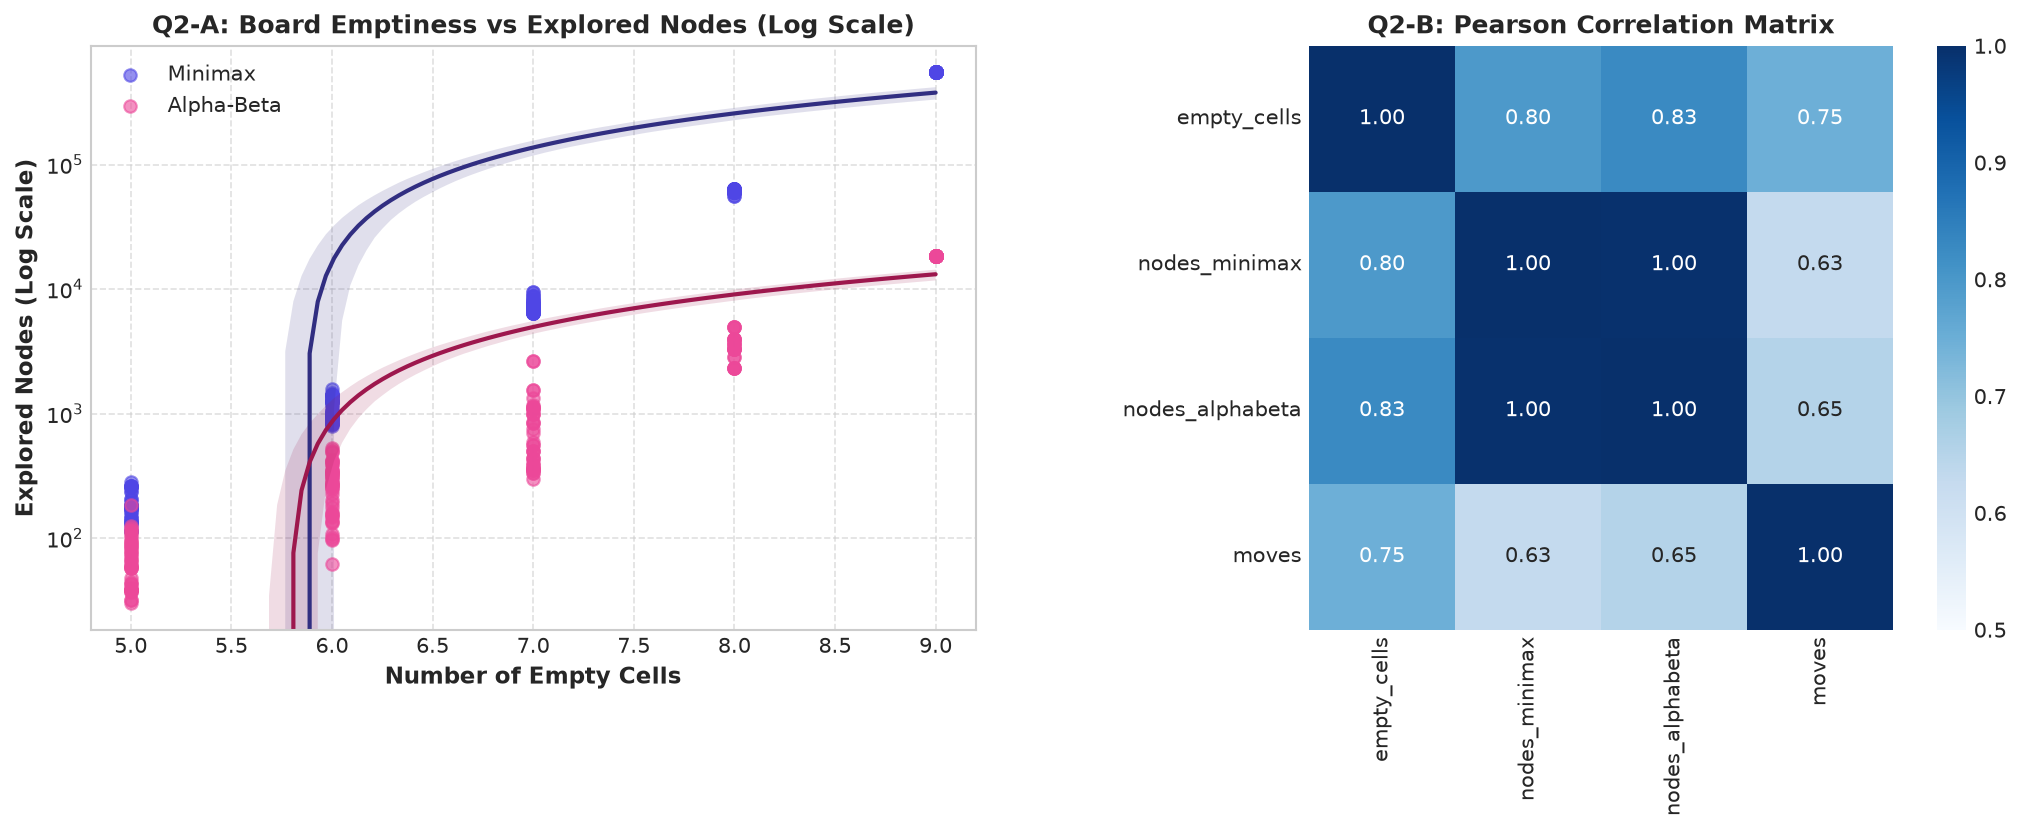

In [5]:
q2 = g.groupby("empty_cells").agg(
    games=("game_id", "count"),
    mm_mean=("nodes_minimax", "mean"), mm_median=("nodes_minimax", "median"), mm_std=("nodes_minimax", "std"),
    ab_mean=("nodes_alphabeta", "mean"), ab_median=("nodes_alphabeta", "median"), ab_std=("nodes_alphabeta", "std"),
)
print(q2.to_string())
print()
print("همبستگی پیرسون (مقدار خام):")
print("  empty_cells با nodes_minimax:   ", round(g.empty_cells.corr(g.nodes_minimax), 3))
print("  empty_cells با nodes_alphabeta: ", round(g.empty_cells.corr(g.nodes_alphabeta), 3))
print("همبستگی پیرسون با لگاریتم گره‌ها (log10):")
print("  empty_cells با log10(nodes_minimax):   ", round(g.empty_cells.corr(np.log10(g.nodes_minimax)), 3))
print("  empty_cells با log10(nodes_alphabeta): ", round(g.empty_cells.corr(np.log10(g.nodes_alphabeta)), 3))
print()
print("ضریب رشد میانگین Minimax به ازای یک خانه خالی بیشتر:")
m = q2.mm_mean
print((m / m.shift(1)).dropna().round(2).to_string())

             games    mm_mean  mm_median   mm_std   ab_mean  ab_median  ab_std
empty_cells                                                                   
5               44     183.66     180.00    47.19     69.61      62.00   32.75
6               47   1,106.49   1,055.00   220.96    274.43     276.00  121.14
7               42   7,387.90   7,332.00   810.21    802.36     575.50  552.71
8               27  60,949.44  59,705.00 2,556.04  3,514.67   3,574.00  829.54
9               40 549,946.00 549,946.00     0.00 18,297.00  18,297.00    0.00

همبستگی پیرسون (مقدار خام):
  empty_cells با nodes_minimax:    0.796
  empty_cells با nodes_alphabeta:  0.827
همبستگی پیرسون با لگاریتم گره‌ها (log10):
  empty_cells با log10(nodes_minimax):    0.998
  empty_cells با log10(nodes_alphabeta):  0.974

ضریب رشد میانگین Minimax به ازای یک خانه خالی بیشتر:
empty_cells
6   6.02
7   6.68
8   8.25
9   9.02


## ۴. نمودار Q5: طول بازی (`moves`) به تفکیک برنده

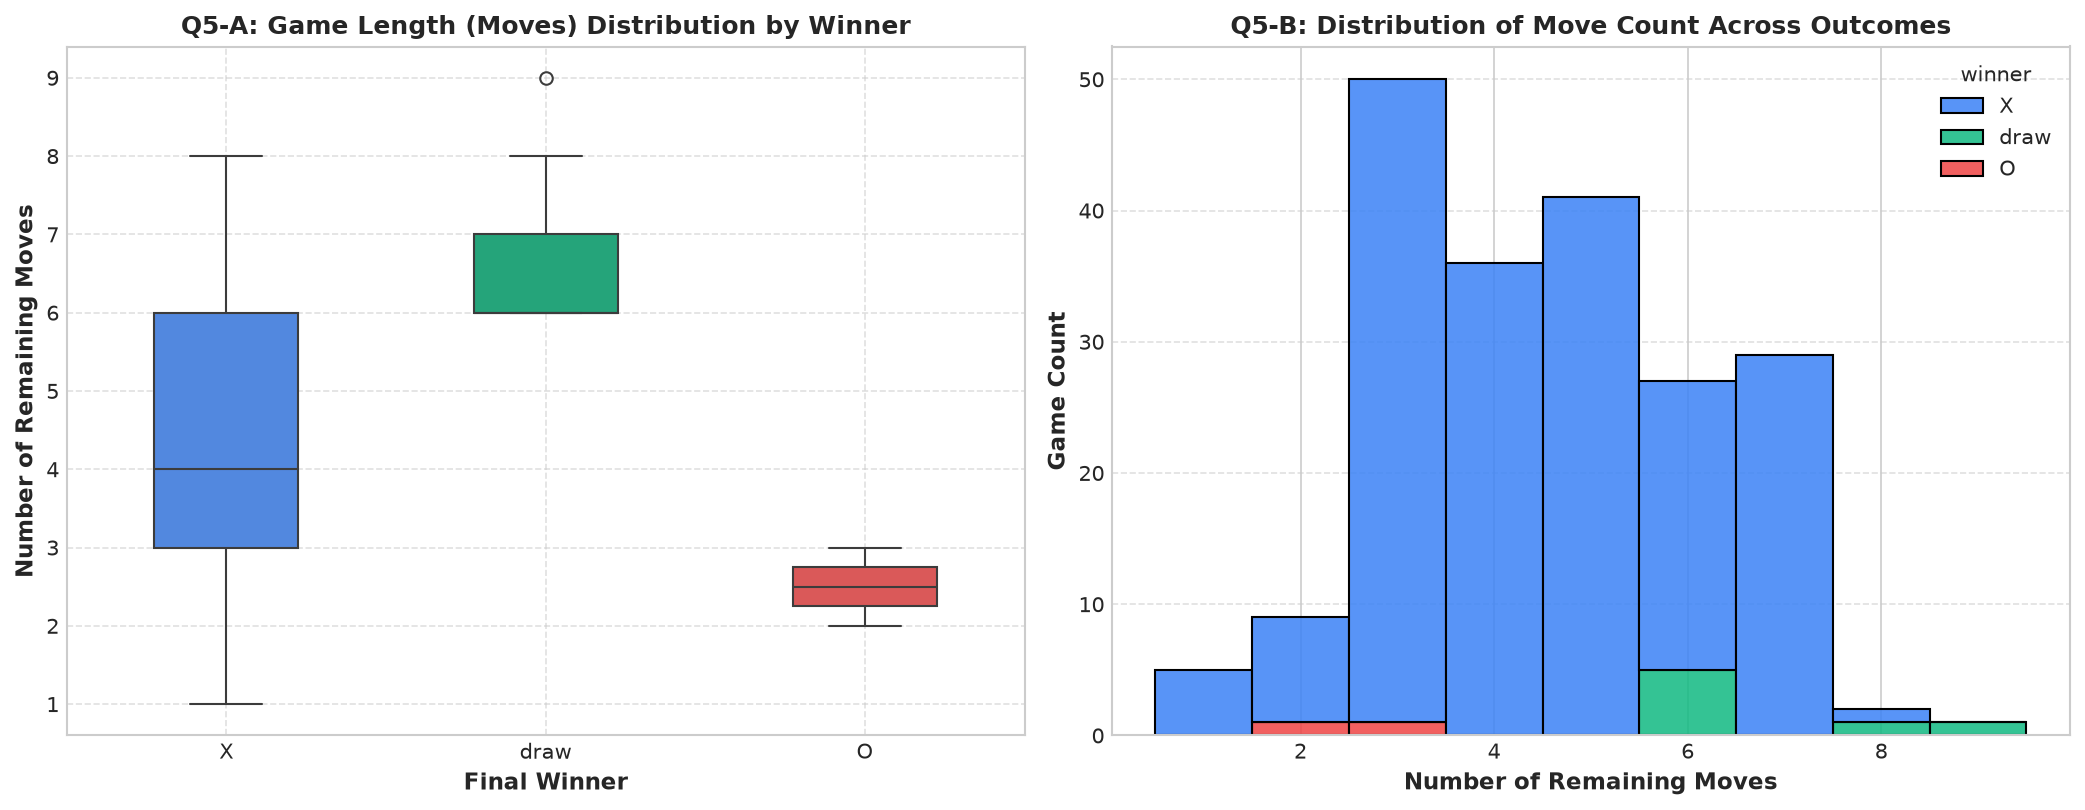

In [6]:
q5 = g.groupby("winner")["moves"].agg(["count", "mean", "median", "var", "std", "min", "max"])
print(q5.to_string())
print()
print("شمار بازی‌ها به ازای هر مقدار moves (ارتفاع میله‌های هیستوگرام Q5-B):")
print(g["moves"].value_counts().sort_index().to_string())

        count  mean  median  var  std  min  max
winner                                         
O           2  2.50    2.50 0.50 0.71    2    3
X         191  4.50    4.00 2.55 1.60    1    8
draw        7  6.71    6.00 1.57 1.25    6    9

شمار بازی‌ها به ازای هر مقدار moves (ارتفاع میله‌های هیستوگرام Q5-B):
moves
1     5
2     9
3    50
4    36
5    41
6    27
7    29
8     2
9     1


## ۵. تفسیر کوتاه (بر اساس خروجی‌های بالا)

- **Q1-A:** میانه گره‌های Minimax برابر 6,812 و Alpha-Beta برابر 427 است. میانگین‌ها (120,069 و 4,382) خیلی بالاتر از میانه‌اند، یعنی توزیع راست‌کج است و فقط چند بازی (شروع از تخته خالی) مقدار بیشینه (549,946 و 18,297) را می‌سازند. به همین دلیل محور لگاریتمی لازم بوده است.
- **Q1-B:** نسبت میانگین‌ها از 30.1 برابر (۰ حرکت اولیه) به 2.6 برابر (۴ حرکت اولیه) کاهش می‌یابد؛ هرچه تخته پرتر باشد، هرس آلفا-بتا سود کمتری دارد.
- **Q2:** میانگین گره‌های Minimax با هر خانه خالی بیشتر حدود 6.0 تا 9.0 برابر می‌شود؛ یعنی رشد نمایی، نه خطی. همبستگی خطی خام 0.80 است ولی با لگاریتم گره‌ها 0.998 (Minimax) و 0.974 (Alpha-Beta) می‌شود.
- **Q5:** میانگین `moves` برای برد X برابر 4.50 (میانه 4.0، انحراف معیار 1.60)، برای مساوی 6.71 و برای برد O فقط 2.50 است. گروه‌ها کوچک‌اند: برد O فقط 2 بازی و مساوی 7 بازی دارد، پس میانگین و انحراف معیار آن‌ها پایدار نیست.
- **نکته:** ۴۰ بازی از ۲۰۰ بازی از تخته خالی شروع شده‌اند و ردیف تکراری وجود دارد؛ آمار روی همه ۲۰۰ ردیف و بدون حذف تکراری‌ها حساب شده است.

## ۶. نکات QA درباره نمودارها و متن‌های گروه

1. **کاهش کل گره‌ها:** خروجی `eda.ipynb` (سلول ۶) عدد ‎96.35٪ را چاپ می‌کند ولی متن تفسیر Q1، نتیجه‌گیری نهایی و README عدد ‎«۹۲٫۸٪»‎ را نوشته‌اند. عدد درست ‎96.35٪ است.
2. **درصدهای Q6:** خروجی `eda.ipynb` برای نوبت X نرخ برد ‎98.4٪ و برای نوبت O ‎90.5٪ را نشان می‌دهد، ولی متن تفسیر و README ‎«۹۸٪»‎ و ‎«۹۱٪»‎ نوشته‌اند.
3. **نمودار Q2-A:** خط‌های رگرسیون روی مقادیر خام برازش شده‌اند ولی روی محور لگاریتمی کشیده شده‌اند؛ به همین دلیل خط‌ها منحنی غیرعادی دارند و باید روی `log10` گره‌ها برازش شوند. همبستگی با لگاریتم بالای ۰٫۹۷ است.
4. **برچسب محور Q5:** محور «Number of Remaining Moves» نوشته شده، ولی `moves` تعداد حرکات انجام‌شده از تخته شروع تا پایان بازی است (نه حرکات باقی‌مانده).

این موارد باید به صاحبان نوت‌بوک EDA و README گزارش شود؛ اصلاح آن‌ها با من نیست.